# SCMS Delivery Performance
## Executive Research & Statistical Findings

**A supply-chain delivery performance investigation | Historical dataset: 2007–2015**

---

### Executive mandate

This notebook evaluates whether shipment mode, fulfillment strategy, vendor, destination country, product group, and manufacturing site are associated with differences in delivery timing.

It is designed as an **executive research report that happens to be reproducible in Python**. Run the notebook from top to bottom. Each analytical section writes its findings, tables, and charts into the report itself.

**PDF presentation:** the code is retained in the notebook for auditability, but the PDF export excludes code cells. The exported report contains corporate narrative, calculated values, tables, and figures only.

> **Important:** This is an observational analysis. Statistical association is not proof of causation or supplier / route superiority.

## 1. Executive Summary

### The delivery-history sample shows statistically significant differences across every tested supply-chain dimension.

The cleaned analytical population contains **9,783 line-item records** representing **6,669 unique shipments**. At shipment grain, **12.0% were late**, **61.5% arrived on schedule**, and **26.5% arrived early**. Median delay was **0 days**, while mean delay was **−4.98 days**; the negative mean reflects the early-delivery tail and should not be read as evidence that the network consistently performs ahead of schedule.

| Research dimension | Statistical finding | Effect / additional evidence |
|---|---|---|
| Shipment mode (H1) | H = 555.00; p < 0.001 | ε² = 0.0828; all 6 mode pairs significant after Holm correction |
| Fulfillment strategy (H2) | U = 7,217,153.5; p < 0.001 | Rank-biserial = 0.3007 |
| Vendor (H3) | H = 269.53; p < 0.001 | ε² = 0.0782; 31 of 153 pairs significant after Holm correction |
| Destination country (H4) | H = 328.67; p < 0.001 | ε² = 0.0470; 54 of 253 pairs significant after Holm correction |
| Product group (H5) | U = 3,019,437; p < 0.001 | Rank-biserial = −0.1837 for ARV relative to HRDT |
| Manufacturing site (H10) | Wald χ²(26) = 192.11; p < 0.001 | Clustered GEE global site term |

### Executive interpretation

- **Transport mode and destination are meaningful segmentation dimensions.** Their group distributions differ, but mode and route mix may explain part of the observed variation.
- **Vendor differences warrant controlled supplier reviews, not a raw league table.** Suppliers serve different products, destinations, modes and periods.
- **Direct Drop and From RDC differ in their delay distributions.** Both have a median delay of zero; their early and late tails must be compared before choosing an operating model.
- **Manufacturing-site differences remain preliminary.** The clustered model accounts for repeated line items within shipments but does not adjust for other operational factors.

### Decision boundary

These are **observational associations**, not causal effects. Complete-case filtering may have changed the composition of the sample. H6–H9 were not tested because the required weight, freight-cost and procurement-date fields were removed from the agreed analytical scope. “Not tested” does not mean “rejected.”

## 2. Research Questions & Hypothesis Register

| ID | Research question | Planned analysis |
|---|---|---|
| H1 | Does transportation mode relate to delivery delay? | Kruskal–Wallis; pairwise Mann–Whitney with Holm correction |
| H2 | Does fulfillment strategy relate to delivery delay? | Mann–Whitney U |
| H3 | Do delivery-delay distributions differ across vendors? | Kruskal–Wallis; pairwise Mann–Whitney with Holm correction |
| H4 | Do delivery-delay distributions differ across destination countries? | Kruskal–Wallis; pairwise Mann–Whitney with Holm correction |
| H5 | Do ARV and HRDT delivery-delay distributions differ? | Mann–Whitney U |
| H10 | Are delivery-delay outcomes associated with manufacturing site? | GEE with shipment-clustered robust covariance |

H6–H9 are not included in the inferential test set because their required fields were removed in the agreed cleaning scope. Their absence must not be interpreted as evidence that those hypotheses are false.

## 3. Analytical Scope & Definitions

**Unit of analysis.** The source file contains line-item records. H1–H5 use one record per shipment identifier (`asn_dn`) to avoid treating multiple lines in the same shipment as independent observations. The shipment-level delay is the median of the line-item delays within that shipment.

**H10 exception.** Manufacturing site varies within some shipments. H10 therefore retains line-level observations and clusters standard errors by shipment identifier.

**Delivery delay (calendar days).**

- Positive value: delivered after scheduled date (late).
- Zero: delivered on scheduled date (on time).
- Negative value: delivered before scheduled date (early).

**Inference threshold.** For vendor, country, product-group, and manufacturing-site screening, categories with fewer than 30 observations are excluded from the relevant inferential comparison and remain descriptive-only where appropriate. This is a practical screening convention, not a universal statistical power rule.

**Multiple testing.** Holm correction is used for the H1, H3, and H4 pairwise comparison families.

## 4. Data Source & Reproducibility

Place `SCMS_Delivery_History_Dataset_20150929.csv` in the same folder as this notebook. The source is loaded as `raw_data`; transformations are performed on a separate `analysis_data` copy.

The cleaning scope intentionally removes six columns: procurement sent date, freight cost, shipment weight, PQ first-sent date, dosage, and item description. Complete-case filtering is then applied to the retained analysis fields. This choice can introduce selection bias if missingness is related to delivery outcomes; the report therefore treats findings as applying to the retained sample.

### 4.1 Load libraries and configure the report

In [ ]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mistune
import numpy as np
import pandas as pd
from IPython.display import HTML, display

markdown_renderer = mistune.create_markdown(plugins=['table'])
from itertools import combinations

from scipy.stats import kruskal, mannwhitneyu
from statsmodels.genmod.cov_struct import Independence
from statsmodels.genmod.families import Gaussian
from statsmodels.genmod.generalized_estimating_equations import GEE
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / "SCMS_Delivery_History_Dataset_20150929.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Place the CSV beside this notebook."
    )

ALPHA = 0.05
MIN_GROUP_SIZE = 30

plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 120,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "grid.linestyle": "--",
    "font.family": "DejaVu Sans"
})

def md(text):
    # Render narrative as HTML so notebook, HTML, and PDF exporters display it consistently.
    display(HTML(markdown_renderer(text)))

def fmt_p(value):
    if value < 0.001:
        return "< 0.001"
    return f"{value:.4f}"

def effect_label(value):
    magnitude = abs(value)
    if magnitude < 0.147:
        return "negligible"
    if magnitude < 0.33:
        return "small"
    if magnitude < 0.474:
        return "medium"
    return "large"

def pairwise_mann_whitney(groups, name_1="group_1", name_2="group_2"):
    results = []
    for first, second in combinations(groups.keys(), 2):
        x = np.asarray(groups[first])
        y = np.asarray(groups[second])
        u_stat, p_value = mannwhitneyu(
            x, y, alternative="two-sided", method="auto"
        )
        delta = (2 * u_stat / (len(x) * len(y))) - 1
        results.append({
            name_1: first,
            name_2: second,
            "n_1": len(x),
            "n_2": len(y),
            "median_1": float(np.median(x)),
            "median_2": float(np.median(y)),
            "U_statistic": float(u_stat),
            "p_value": float(p_value),
            "cliffs_delta": float(delta)
        })
    result = pd.DataFrame(results)
    if not result.empty:
        result["p_adjusted_holm"] = multipletests(
            result["p_value"], method="holm"
        )[1]
        result["significant"] = result["p_adjusted_holm"] < ALPHA
        result = result.sort_values("p_adjusted_holm").reset_index(drop=True)
    return result

### 4.2 Load and preserve the source data

In [2]:
raw_data = pd.read_csv(DATA_PATH, encoding="latin-1")

# Standardize column names once; keep the source values untouched.
raw_data.columns = (
    raw_data.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s*#\s*", "", regex=True)
    .str.replace("/", " ", regex=False)
    .str.replace(r"\s+", "_", regex=True)
)

analysis_data = raw_data.copy()

md(
    f"**Source loaded successfully.** The source contains "
    f"**{len(raw_data):,} rows** and **{raw_data.shape[1]} columns**."
)
display(raw_data.head(5))

,id,project_code,pq,po_so,asn_dn,country,managed_by,fulfill_via,vendor_inco_term,shipment_mode,...,unit_of_measure_(per_pack),line_item_quantity,line_item_value,pack_price,unit_price,manufacturing_site,first_line_designation,weight_(kilograms),freight_cost_(usd),line_item_insurance_(usd)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


## 5. Data Preparation & Quality Review

The following steps preserve the raw source, standardize date and numeric fields, apply the agreed column exclusions, and create the delivery-performance outcome.

### 5.1 Convert data types

In [3]:
date_columns = [
    "pq_first_sent_to_client_date",
    "po_sent_to_vendor_date",
    "scheduled_delivery_date",
    "delivered_to_client_date",
    "delivery_recorded_date"
]

for column in date_columns:
    if column in analysis_data.columns:
        analysis_data[column] = pd.to_datetime(
            analysis_data[column], format="mixed", errors="coerce"
        )

numeric_columns = [
    "weight_(kilograms)",
    "freight_cost_(usd)",
    "line_item_insurance_(usd)",
    "line_item_value"
]

for column in numeric_columns:
    if column in analysis_data.columns:
        analysis_data[column] = pd.to_numeric(
            analysis_data[column], errors="coerce"
        )

md("Date and numeric conversion completed. Invalid values, if any, are represented as missing values and handled by the documented filtering step.")

### 5.2 Apply the agreed analytical scope

In [4]:
columns_to_drop = [
    "po_sent_to_vendor_date",
    "freight_cost_(usd)",
    "weight_(kilograms)",
    "pq_first_sent_to_client_date",
    "dosage",
    "item_description"
]

existing_drop_columns = [
    column for column in columns_to_drop if column in analysis_data.columns
]
analysis_data = analysis_data.drop(columns=existing_drop_columns).copy()

rows_before_complete_case = len(analysis_data)
analysis_data = analysis_data.dropna().copy()
rows_after_complete_case = len(analysis_data)
rows_removed_complete_case = rows_before_complete_case - rows_after_complete_case

quality_summary = pd.DataFrame({
    "Measure": [
        "Original source rows",
        "Rows before complete-case filtering",
        "Rows retained",
        "Rows removed by complete-case filtering",
        "Removed share of pre-filter rows",
        "Columns removed by scope",
        "Missing values after filtering",
        "Duplicate full rows after filtering"
    ],
    "Result": [
        f"{len(raw_data):,}",
        f"{rows_before_complete_case:,}",
        f"{rows_after_complete_case:,}",
        f"{rows_removed_complete_case:,}",
        f"{rows_removed_complete_case / max(rows_before_complete_case, 1):.1%}",
        ", ".join(existing_drop_columns),
        f"{int(analysis_data.isna().sum().sum()):,}",
        f"{int(analysis_data.duplicated().sum()):,}"
    ]
})

display(quality_summary)

,Measure,Result
0,Original source rows,"10,324"
1,Rows before complete-case filtering,"10,324"
2,Rows retained,"9,783"
3,Rows removed by complete-case filtering,541
4,Removed share of pre-filter rows,5.2%
5,Columns removed by scope,"po_sent_to_vendor_date, freight_cost_(usd), we..."
6,Missing values after filtering,0
7,Duplicate full rows after filtering,0


### 5.3 Create delivery-delay and delivery-status measures

In [5]:
required_columns = [
    "asn_dn", "scheduled_delivery_date", "delivered_to_client_date",
    "shipment_mode", "fulfill_via", "vendor", "country",
    "product_group", "manufacturing_site"
]
missing_required = [
    column for column in required_columns if column not in analysis_data.columns
]
if missing_required:
    raise KeyError(f"Required analytical columns missing: {missing_required}")

analysis_data["delivery_delay_days"] = (
    analysis_data["delivered_to_client_date"]
    - analysis_data["scheduled_delivery_date"]
).dt.days

analysis_data["delivery_status"] = np.select(
    [
        analysis_data["delivery_delay_days"] > 0,
        analysis_data["delivery_delay_days"] < 0
    ],
    ["Late", "Early"],
    default="On Time"
)

delay_profile = analysis_data["delivery_delay_days"].describe().to_frame("Line-item delay (days)")
display(delay_profile)

,Line-item delay (days)
count,9783.000000
mean,-6.275580
std,27.622009
min,-372.000000
25%,-5.000000
50%,0.000000
75%,0.000000
max,192.000000


### 5.4 Validate shipment grain and within-shipment consistency

The source has repeated line-item records within shipment identifiers. The next checks quantify that structure and identify variables that vary within a shipment.

In [6]:
shipment_sizes = analysis_data.groupby("asn_dn").size()
shipment_variables = [
    "delivery_delay_days", "shipment_mode", "fulfill_via",
    "vendor", "country", "product_group", "manufacturing_site"
]
shipment_consistency = (
    analysis_data.groupby("asn_dn")[shipment_variables].nunique()
)

shipment_audit = pd.DataFrame({
    "Measure": [
        "Line-item observations",
        "Unique shipment identifiers",
        "Shipments with multiple line records",
        "Maximum line records in one shipment",
        "Shipments with multiple delivery-delay values",
        "Shipments with multiple manufacturing sites"
    ],
    "Result": [
        f"{len(analysis_data):,}",
        f"{analysis_data['asn_dn'].nunique():,}",
        f"{int((shipment_sizes > 1).sum()):,}",
        f"{int(shipment_sizes.max()):,}",
        f"{int((shipment_consistency['delivery_delay_days'] > 1).sum()):,}",
        f"{int((shipment_consistency['manufacturing_site'] > 1).sum()):,}"
    ]
})
display(shipment_audit)

,Measure,Result
0,Line-item observations,"9,783"
1,Unique shipment identifiers,"6,669"
2,Shipments with multiple line records,"1,368"
3,Maximum line records in one shipment,54
4,Shipments with multiple delivery-delay values,10
5,Shipments with multiple manufacturing sites,835


### 5.5 Build the shipment-level analytical population

H1–H5 use the median line-item delay within each shipment. This prevents repeated lines from artificially inflating the sample size. Manufacturing site is intentionally excluded from this aggregation because it can vary within a shipment.

In [7]:
shipment_data = (
    analysis_data
    .groupby("asn_dn", as_index=False)
    .agg(
        delivery_delay_days=("delivery_delay_days", "median"),
        shipment_mode=("shipment_mode", "first"),
        fulfill_via=("fulfill_via", "first"),
        vendor=("vendor", "first"),
        country=("country", "first"),
        product_group=("product_group", "first")
    )
)

assert shipment_data["asn_dn"].is_unique
assert shipment_data.isna().sum().sum() == 0

shipment_delay_profile = shipment_data["delivery_delay_days"].describe()
shipment_status = np.select(
    [
        shipment_data["delivery_delay_days"] > 0,
        shipment_data["delivery_delay_days"] < 0
    ],
    ["Late", "Early"],
    default="On Time"
)
status_counts = pd.Series(shipment_status).value_counts()
status_percentages = pd.Series(shipment_status).value_counts(normalize=True) * 100

overall_kpis = pd.DataFrame({
    "KPI": [
        "Unique shipments",
        "Late shipments",
        "Late shipment rate",
        "On-time shipments",
        "On-time rate",
        "Early shipments",
        "Early shipment rate",
        "Mean shipment delay",
        "Median shipment delay",
        "90th percentile delay"
    ],
    "Value": [
        f"{len(shipment_data):,}",
        f"{int(status_counts.get('Late', 0)):,}",
        f"{status_percentages.get('Late', 0):.2f}%",
        f"{int(status_counts.get('On Time', 0)):,}",
        f"{status_percentages.get('On Time', 0):.2f}%",
        f"{int(status_counts.get('Early', 0)):,}",
        f"{status_percentages.get('Early', 0):.2f}%",
        f"{shipment_data['delivery_delay_days'].mean():.2f} days",
        f"{shipment_data['delivery_delay_days'].median():.0f} days",
        f"{shipment_data['delivery_delay_days'].quantile(.90):.0f} days"
    ]
})
display(overall_kpis)

,KPI,Value
0,Unique shipments,"6,669"
1,Late shipments,798
2,Late shipment rate,11.97%
3,On-time shipments,"4,101"
4,On-time rate,61.49%
5,Early shipments,"1,770"
6,Early shipment rate,26.54%
7,Mean shipment delay,-4.98 days
8,Median shipment delay,0 days
9,90th percentile delay,3 days


## 6. Overall Delivery Performance

The distribution is highly asymmetric: many shipments are exactly on schedule, while the early-delivery tail pulls the mean below zero. Averages must therefore be interpreted alongside late rate, on-time rate, early rate, and upper-tail delay.

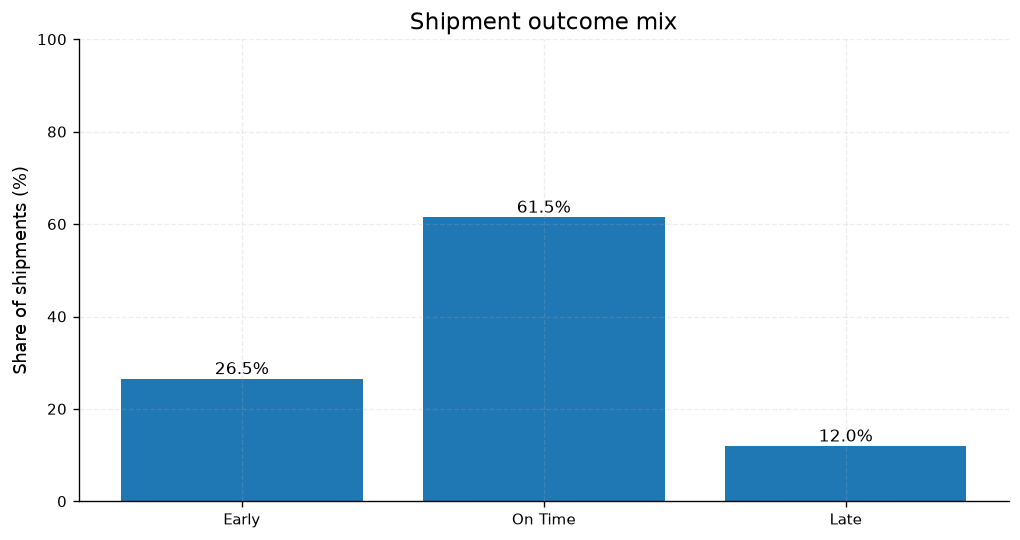

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
status_order = ["Early", "On Time", "Late"]
status_values = [status_percentages.get(label, 0) for label in status_order]
bars = ax.bar(status_order, status_values)
ax.set_title("Shipment outcome mix")
ax.set_ylabel("Share of shipments (%)")
ax.set_ylim(0, 100)
for bar, value in zip(bars, status_values):
    ax.text(bar.get_x() + bar.get_width()/2, value + 1, f"{value:.1f}%", ha="center")
plt.show()

md(
    f"**Delivery outcome:** {status_percentages.get('Late', 0):.1f}% of shipments were late, "
    f"{status_percentages.get('On Time', 0):.1f}% arrived on schedule, and "
    f"{status_percentages.get('Early', 0):.1f}% arrived early. "
    f"The shipment-level mean delay was {shipment_data['delivery_delay_days'].mean():.2f} days "
    f"and the median was {shipment_data['delivery_delay_days'].median():.0f} days."
)

## 7. H1 — Shipment Mode

**Question:** Do delivery-delay distributions differ across Air, Air Charter, Ocean, and Truck shipments?

The Kruskal–Wallis test evaluates the global difference. Pairwise Mann–Whitney tests identify which pairs differ; Holm correction controls family-wise error across the six comparisons.

,shipments,mean_delay,median_delay,std_dev
shipment_mode,,,,
Air Charter,494,-19.152,-13.0,29.943
Truck,1442,-9.623,0.0,30.907
Air,4406,-2.707,0.0,18.939
Ocean,327,6.343,0.0,22.601


,mode_1,mode_2,n_1,n_2,median_1,median_2,U_statistic,p_value,cliffs_delta,p_adjusted_holm,significant
0,Air,Air Charter,4406,494,0.0,-13.0,1612258.0,0.0,0.48147,0.0,True
1,Air Charter,Ocean,494,327,-13.0,0.0,31052.5,0.0,-0.61554,0.0,True
2,Air,Truck,4406,1442,0.0,0.0,3758089.5,0.0,0.18301,0.0,True
3,Ocean,Truck,327,1442,0.0,0.0,318637.0,0.0,0.35149,0.0,True
4,Air Charter,Truck,494,1442,-13.0,0.0,261628.5,0.0,-0.26545,0.0,True
5,Air,Ocean,4406,327,0.0,0.0,571524.0,0.0,-0.20664,0.0,True


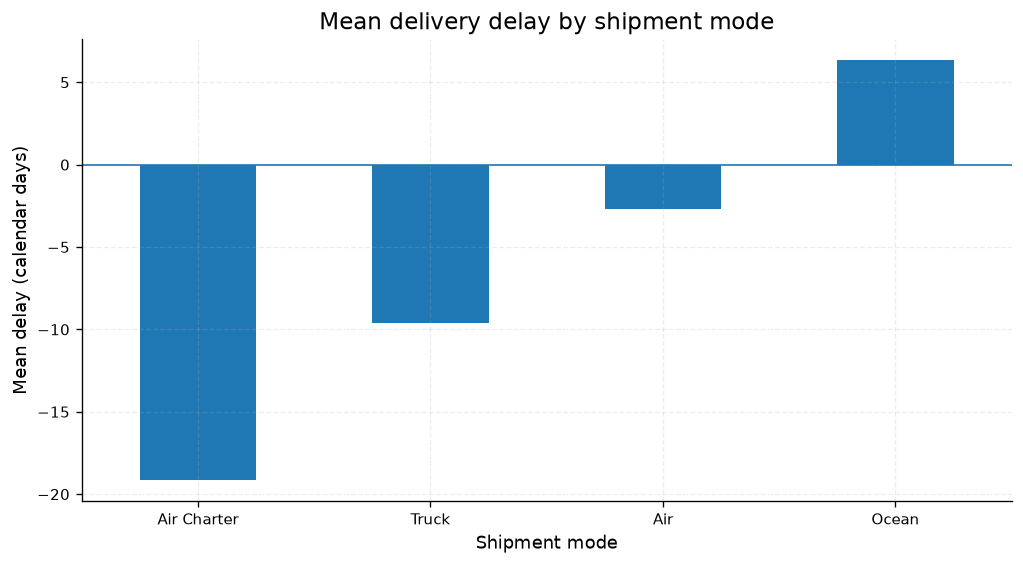

In [9]:
h1_groups = {
    mode: group["delivery_delay_days"].to_numpy()
    for mode, group in shipment_data.groupby("shipment_mode")
}
h1_summary = (
    shipment_data.groupby("shipment_mode")["delivery_delay_days"]
    .agg(shipments="count", mean_delay="mean", median_delay="median", std_dev="std")
    .sort_values("mean_delay")
)
h1_stat, h1_p = kruskal(*h1_groups.values())
h1_n, h1_k = len(shipment_data), len(h1_groups)
h1_epsilon_squared = (h1_stat - h1_k + 1) / (h1_n - h1_k)
h1_posthoc = pairwise_mann_whitney(h1_groups, "mode_1", "mode_2")

display(h1_summary.round(3))
display(h1_posthoc.round(5))

fig, ax = plt.subplots(figsize=(10, 5))
h1_summary["mean_delay"].sort_values().plot(kind="bar", ax=ax)
ax.axhline(0, linewidth=1)
ax.set_title("Mean delivery delay by shipment mode")
ax.set_ylabel("Mean delay (calendar days)")
ax.set_xlabel("Shipment mode")
plt.xticks(rotation=0)
plt.show()

md(
    f"### H1 finding — {'Supported' if h1_p < ALPHA else 'Not supported'}\n\n"
    f"The global test returned **H = {h1_stat:.3f}**, **p = {fmt_p(h1_p)}**, "
    f"and **epsilon-squared = {h1_epsilon_squared:.4f}**. "
    f"{int(h1_posthoc['significant'].sum())} of {len(h1_posthoc)} pairwise comparisons "
    f"remained significant after Holm correction. "
    f"The highest mean delay was **{h1_summary['mean_delay'].idxmax()}** "
    f"({h1_summary['mean_delay'].max():.2f} days); the lowest was "
    f"**{h1_summary['mean_delay'].idxmin()}** ({h1_summary['mean_delay'].min():.2f} days).\n\n"
    f"**Interpretation:** shipment mode is associated with delivery-delay distribution. "
    f"The result does not establish that changing modes would cause the observed difference."
)

## 8. H2 — Fulfillment Strategy

**Question:** Do Direct Drop and From RDC shipments have different delivery-delay distributions?

The Mann–Whitney U test compares the two independent shipment-level groups. The rank-biserial correlation describes the direction and magnitude of the rank-distribution difference.

,shipments,mean_delay,median_delay,std_dev
fulfill_via,,,,
Direct Drop,3481,-0.522,0.0,18.064
From RDC,3188,-9.841,0.0,27.896


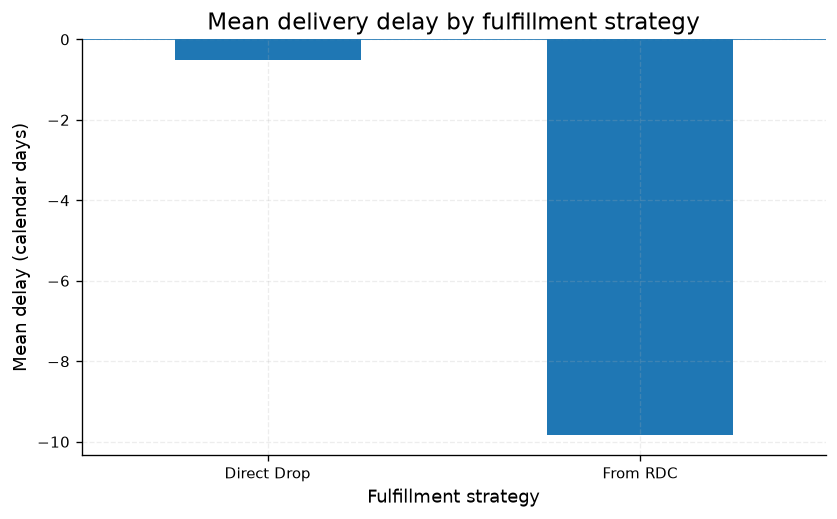

In [10]:
h2_groups = {
    strategy: group["delivery_delay_days"].to_numpy()
    for strategy, group in shipment_data.groupby("fulfill_via")
}
h2_summary = (
    shipment_data.groupby("fulfill_via")["delivery_delay_days"]
    .agg(shipments="count", mean_delay="mean", median_delay="median", std_dev="std")
)
direct_drop = h2_groups.get("Direct Drop")
from_rdc = h2_groups.get("From RDC")

h2_u, h2_p = mannwhitneyu(
    direct_drop, from_rdc, alternative="two-sided", method="auto"
)
h2_rank_biserial = 2 * h2_u / (len(direct_drop) * len(from_rdc)) - 1

display(h2_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
h2_summary["mean_delay"].plot(kind="bar", ax=ax)
ax.axhline(0, linewidth=1)
ax.set_title("Mean delivery delay by fulfillment strategy")
ax.set_ylabel("Mean delay (calendar days)")
ax.set_xlabel("Fulfillment strategy")
plt.xticks(rotation=0)
plt.show()

md(
    f"### H2 finding — {'Supported' if h2_p < ALPHA else 'Not supported'}\n\n"
    f"Mann–Whitney **U = {h2_u:,.1f}**, **p = {fmt_p(h2_p)}**, "
    f"rank-biserial correlation = **{h2_rank_biserial:.4f}**. "
    f"With Direct Drop passed as the first group, the positive effect indicates that "
    f"Direct Drop observations tend to have higher delay values than From RDC observations.\n\n"
    f"**Interpretation:** the groups differ in their delay distributions. Their medians, "
    f"means, early-delivery tails and late rates should all be considered before making an "
    f"operational choice; this test does not establish a causal fulfillment effect."
)

## 9. H3 — Vendor Performance

**Question:** Do delivery-delay distributions differ across vendors?

The `SCMS from RDC` category is excluded from the supplier comparison because it represents the RDC channel label rather than an ordinary external supplier. Vendors with fewer than 30 shipments are excluded from inference and retained in the sample audit.

,Vendor screening,Count
0,External vendor categories,68
1,Eligible vendors (30+ shipments),18
2,Excluded low-volume vendors,50
3,Shipments in H3,3246


,shipments,mean_delay,median_delay,std_dev
vendor,,,,
"Orgenics, Ltd",667,0.895,0.0,10.194
Aurobindo Pharma Limited,526,5.285,0.0,21.044
ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),330,0.309,0.0,3.350
"Trinity Biotech, Plc",275,-0.047,0.0,0.593
MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORATORIES),250,-0.780,0.0,9.453
HETERO LABS LIMITED,199,-0.244,0.0,1.649
S. BUYS WHOLESALER,191,-28.000,0.0,49.633
CIPLA LIMITED,165,5.067,0.0,20.335
"CHEMBIO DIAGNOSTIC SYSTEMS, INC.",105,-4.181,0.0,15.433


,vendor_1,vendor_2,n_1,n_2,median_1,median_2,U_statistic,p_value,cliffs_delta,p_adjusted_holm,significant
0,Aurobindo Pharma Limited,S. BUYS WHOLESALER,526,191,0.0,0.0,71086.5,0.0,0.41514,0.00000,True
1,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),S. BUYS WHOLESALER,330,191,0.0,0.0,42202.0,0.0,0.33911,0.00000,True
2,"Orgenics, Ltd",S. BUYS WHOLESALER,667,191,0.0,0.0,86404.5,0.0,0.35646,0.00000,True
3,S. BUYS WHOLESALER,"Trinity Biotech, Plc",191,275,0.0,0.0,17585.5,0.0,-0.33040,0.00000,True
4,MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORA...,S. BUYS WHOLESALER,250,191,0.0,0.0,31616.5,0.0,0.32425,0.00000,True
5,CIPLA LIMITED,S. BUYS WHOLESALER,165,191,0.0,0.0,22055.0,0.0,0.39965,0.00000,True
6,HETERO LABS LIMITED,S. BUYS WHOLESALER,199,191,0.0,0.0,24944.5,0.0,0.31256,0.00000,True
7,S. BUYS WHOLESALER,STRIDES ARCOLAB LIMITED,191,83,0.0,0.0,5089.0,0.0,-0.35798,0.00000,True
8,S. BUYS WHOLESALER,"Standard Diagnostics, Inc.",191,93,0.0,0.0,6017.0,0.0,-0.32252,0.00002,True
9,Aurobindo Pharma Limited,"Trinity Biotech, Plc",526,275,0.0,0.0,82240.5,0.0,0.13710,0.00002,True


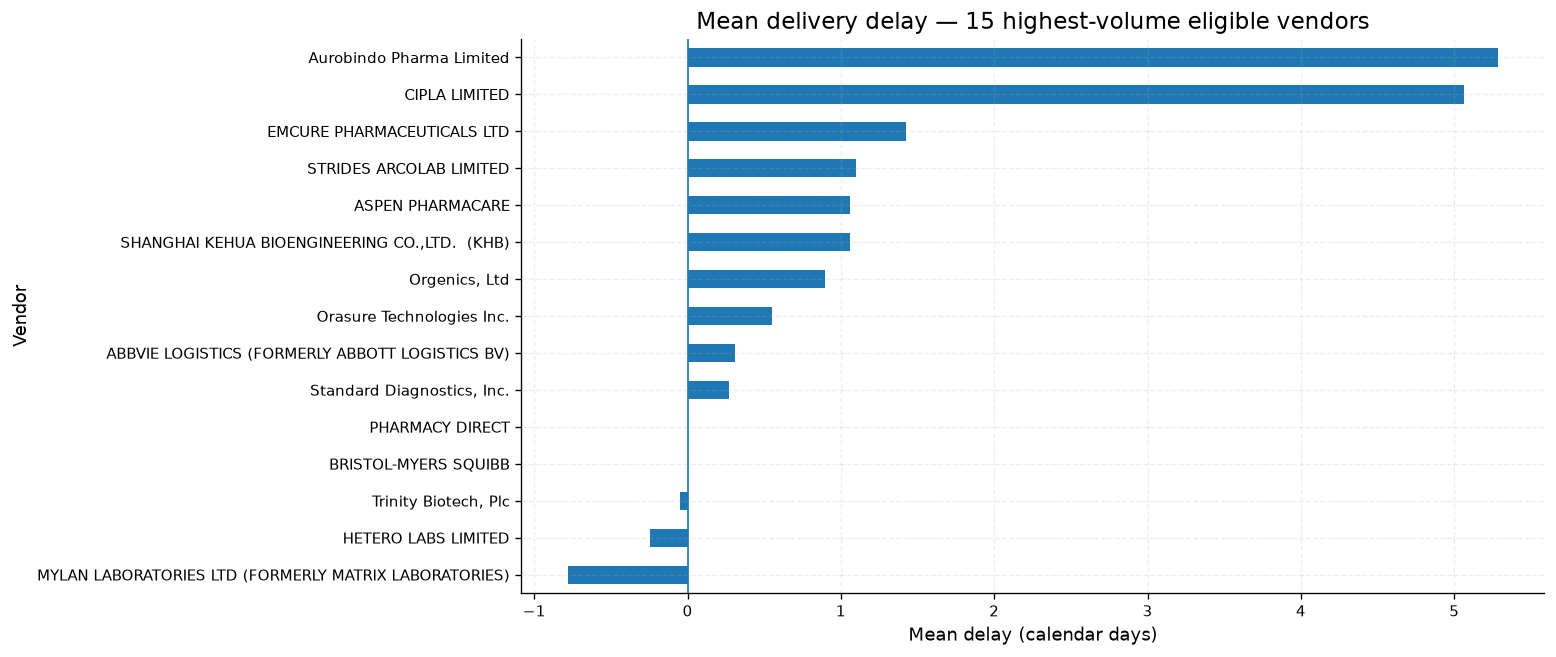

In [11]:
vendor_data = shipment_data.loc[
    shipment_data["vendor"] != "SCMS from RDC"
].copy()

vendor_counts = vendor_data["vendor"].value_counts()
eligible_vendors = vendor_counts[vendor_counts >= MIN_GROUP_SIZE].index
h3_data = vendor_data[vendor_data["vendor"].isin(eligible_vendors)].copy()

h3_groups = {
    vendor: group["delivery_delay_days"].to_numpy()
    for vendor, group in h3_data.groupby("vendor")
}
h3_summary = (
    h3_data.groupby("vendor")["delivery_delay_days"]
    .agg(shipments="count", mean_delay="mean", median_delay="median", std_dev="std")
    .sort_values("shipments", ascending=False)
)
h3_stat, h3_p = kruskal(*h3_groups.values())
h3_n, h3_k = len(h3_data), len(h3_groups)
h3_epsilon_squared = (h3_stat - h3_k + 1) / (h3_n - h3_k)
h3_posthoc = pairwise_mann_whitney(h3_groups, "vendor_1", "vendor_2")

display(pd.DataFrame({
    "Vendor screening": [
        "External vendor categories",
        "Eligible vendors (30+ shipments)",
        "Excluded low-volume vendors",
        "Shipments in H3"
    ],
    "Count": [
        vendor_counts.size,
        len(eligible_vendors),
        int((vendor_counts < MIN_GROUP_SIZE).sum()),
        len(h3_data)
    ]
}))
display(h3_summary.round(3))
display(h3_posthoc.loc[h3_posthoc["significant"]].head(10).round(5))

fig, ax = plt.subplots(figsize=(11, 6))
h3_summary.sort_values("mean_delay").tail(15)["mean_delay"].plot(kind="barh", ax=ax)
ax.axvline(0, linewidth=1)
ax.set_title("Mean delivery delay — 15 highest-volume eligible vendors")
ax.set_xlabel("Mean delay (calendar days)")
ax.set_ylabel("Vendor")
plt.show()

md(
    f"### H3 finding — {'Supported' if h3_p < ALPHA else 'Not supported'}\n\n"
    f"Kruskal–Wallis **H = {h3_stat:.3f}**, **p = {fmt_p(h3_p)}**, "
    f"epsilon-squared = **{h3_epsilon_squared:.4f}**. "
    f"The test includes **{h3_k} vendors** and **{h3_n:,} shipments**. "
    f"Of {len(h3_posthoc)} pairwise comparisons, "
    f"**{int(h3_posthoc['significant'].sum())}** remained significant after Holm correction.\n\n"
    f"**Interpretation:** vendor groups differ in their observed delay distributions. "
    f"This is not a defensible standalone supplier ranking because vendors may serve "
    f"different products, destinations, modes and time periods. Compare suppliers within "
    f"comparable operating conditions before assigning accountability."
)

## 10. H4 — Destination Geography

**Question:** Do delivery-delay distributions differ across destination countries?

Countries with fewer than 30 shipment observations are excluded from inferential testing. The remaining comparisons use Kruskal–Wallis and Holm-adjusted pairwise Mann–Whitney tests.

,Country screening,Count
0,Countries in shipment data,43
1,Eligible countries (30+ shipments),23
2,Excluded low-volume countries,20
3,Shipments in H4,6544


,shipments,mean_delay,median_delay,std_dev
country,,,,
Nigeria,897,-11.693,0.0,26.749
Côte d'Ivoire,674,-6.141,0.0,24.120
Uganda,574,-6.530,0.0,18.752
South Africa,573,-2.743,0.0,40.432
Vietnam,461,-0.639,0.0,7.910
Zambia,439,-5.337,0.0,23.142
Haiti,435,-1.906,0.0,11.436
Tanzania,412,-4.879,0.0,25.215
Mozambique,384,-1.656,0.0,19.627


,country_1,country_2,n_1,n_2,median_1,median_2,U_statistic,p_value,cliffs_delta,p_adjusted_holm,significant
0,Nigeria,Vietnam,897,461,0.0,0.0,134183.0,0.0,-0.35102,0.0,True
1,Nigeria,South Africa,897,573,0.0,0.0,178283.5,0.0,-0.30626,0.0,True
2,Haiti,Nigeria,435,897,0.0,0.0,252931.5,0.0,0.29644,0.0,True
3,Mozambique,Nigeria,384,897,0.0,0.0,221174.0,0.0,0.28422,0.0,True
4,Uganda,Vietnam,574,461,0.0,0.0,104687.0,0.0,-0.20876,0.0,True
5,Vietnam,Zimbabwe,461,322,0.0,0.0,90921.5,0.0,0.22501,0.0,True
6,Kenya,Nigeria,103,897,0.0,0.0,64985.0,0.0,0.40674,0.0,True
7,Côte d'Ivoire,Vietnam,674,461,0.0,0.0,126455.0,0.0,-0.18604,0.0,True
8,"Congo, DRC",Nigeria,113,897,0.0,0.0,69243.0,0.0,0.36627,0.0,True
9,South Africa,Uganda,573,574,0.0,0.0,197133.5,0.0,0.19874,0.0,True


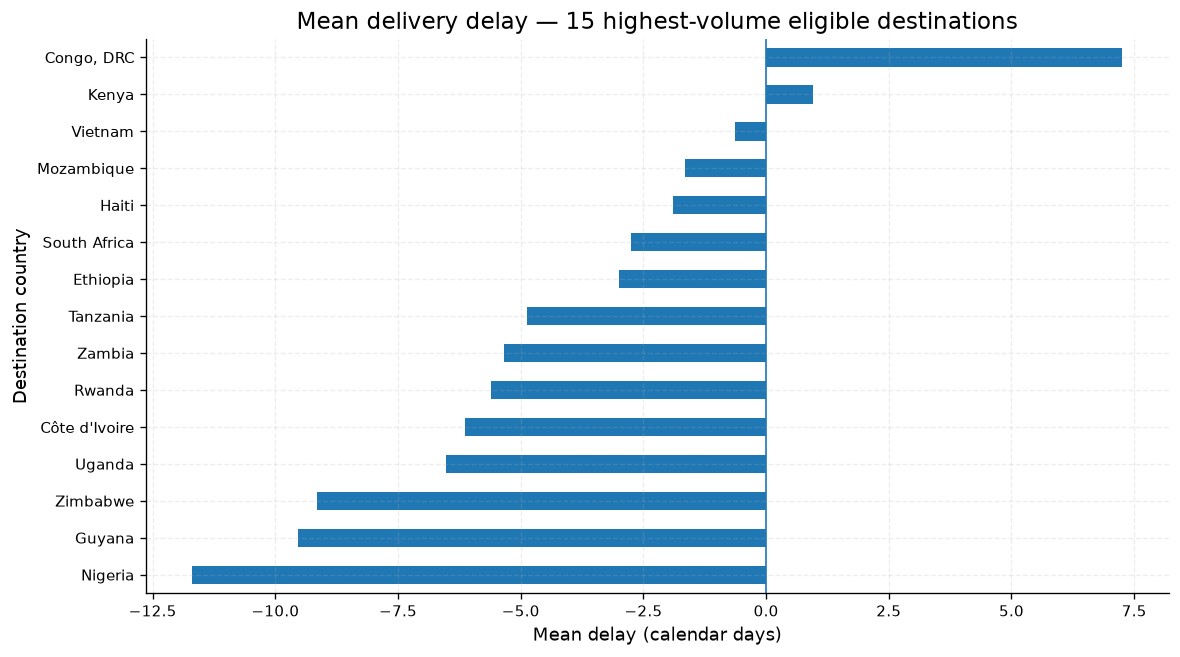

In [12]:
country_counts = shipment_data["country"].value_counts()
eligible_countries = country_counts[country_counts >= MIN_GROUP_SIZE].index
h4_data = shipment_data[shipment_data["country"].isin(eligible_countries)].copy()

h4_groups = {
    country: group["delivery_delay_days"].to_numpy()
    for country, group in h4_data.groupby("country")
}
h4_summary = (
    h4_data.groupby("country")["delivery_delay_days"]
    .agg(shipments="count", mean_delay="mean", median_delay="median", std_dev="std")
    .sort_values("shipments", ascending=False)
)
h4_stat, h4_p = kruskal(*h4_groups.values())
h4_n, h4_k = len(h4_data), len(h4_groups)
h4_epsilon_squared = (h4_stat - h4_k + 1) / (h4_n - h4_k)
h4_posthoc = pairwise_mann_whitney(h4_groups, "country_1", "country_2")

display(pd.DataFrame({
    "Country screening": [
        "Countries in shipment data",
        "Eligible countries (30+ shipments)",
        "Excluded low-volume countries",
        "Shipments in H4"
    ],
    "Count": [
        country_counts.size,
        len(eligible_countries),
        int((country_counts < MIN_GROUP_SIZE).sum()),
        len(h4_data)
    ]
}))
display(h4_summary.round(3))
display(h4_posthoc.loc[h4_posthoc["significant"]].head(10).round(5))

fig, ax = plt.subplots(figsize=(11, 6))
h4_summary.head(15).sort_values("mean_delay").plot(
    kind="barh", y="mean_delay", ax=ax, legend=False
)
ax.axvline(0, linewidth=1)
ax.set_title("Mean delivery delay — 15 highest-volume eligible destinations")
ax.set_xlabel("Mean delay (calendar days)")
ax.set_ylabel("Destination country")
plt.show()

md(
    f"### H4 finding — {'Supported' if h4_p < ALPHA else 'Not supported'}\n\n"
    f"Kruskal–Wallis **H = {h4_stat:.3f}**, **p = {fmt_p(h4_p)}**, "
    f"epsilon-squared = **{h4_epsilon_squared:.4f}**. "
    f"The comparison covers **{h4_k} countries** and **{h4_n:,} shipments**. "
    f"**{int(h4_posthoc['significant'].sum())} of {len(h4_posthoc)}** pairwise comparisons "
    f"remain significant after Holm correction.\n\n"
    f"**Interpretation:** destination country is associated with differences in delivery-delay "
    f"distributions. Country is a proxy for a bundle of route, customs, carrier, supplier and "
    f"operating conditions; this analysis does not isolate a geographic causal effect."
)

## 11. H5 — Product Group

**Question:** Do ARV and HRDT shipments have different delivery-delay distributions?

ARV and HRDT are the only product groups with sufficient sample sizes for the planned comparison. Smaller groups remain descriptive-only.

,shipments,mean_delay,median_delay,std_dev
product_group,,,,
ARV,5210,-6.347,0.0,26.144
HRDT,1420,0.074,0.0,9.304


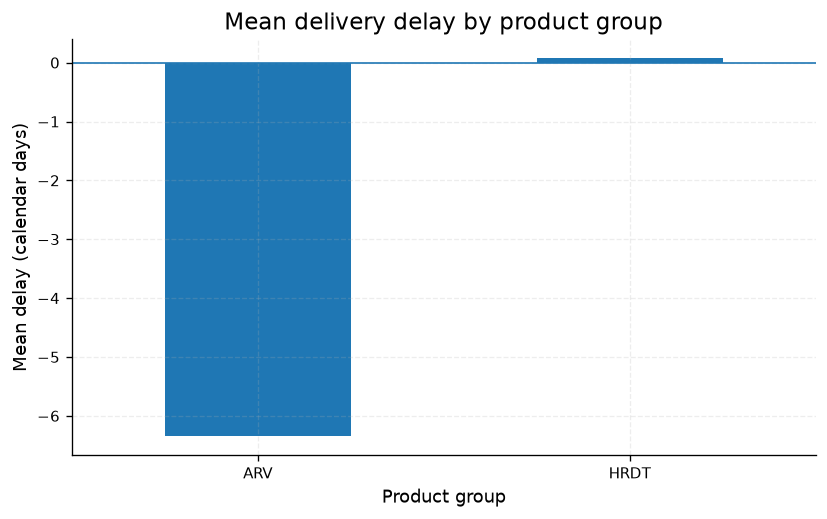

In [13]:
h5_data = shipment_data[
    shipment_data["product_group"].isin(["ARV", "HRDT"])
].copy()

h5_groups = {
    group_name: group["delivery_delay_days"].to_numpy()
    for group_name, group in h5_data.groupby("product_group")
}
h5_summary = (
    h5_data.groupby("product_group")["delivery_delay_days"]
    .agg(shipments="count", mean_delay="mean", median_delay="median", std_dev="std")
)
arv = h5_groups["ARV"]
hrdt = h5_groups["HRDT"]

h5_u, h5_p = mannwhitneyu(
    arv, hrdt, alternative="two-sided", method="auto"
)
h5_rank_biserial = 2 * h5_u / (len(arv) * len(hrdt)) - 1

display(h5_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
h5_summary["mean_delay"].plot(kind="bar", ax=ax)
ax.axhline(0, linewidth=1)
ax.set_title("Mean delivery delay by product group")
ax.set_ylabel("Mean delay (calendar days)")
ax.set_xlabel("Product group")
plt.xticks(rotation=0)
plt.show()

md(
    f"### H5 finding — {'Supported' if h5_p < ALPHA else 'Not supported'}\n\n"
    f"Mann–Whitney **U = {h5_u:,.1f}**, **p = {fmt_p(h5_p)}**, "
    f"rank-biserial correlation = **{h5_rank_biserial:.4f}**. "
    f"The sign is calculated with ARV as the first group; a negative value indicates that "
    f"ARV observations tend to have lower delay values than HRDT observations.\n\n"
    f"**Interpretation:** ARV and HRDT distributions differ statistically. The magnitude of "
    f"the rank effect should guide operational interpretation; a very small p-value alone "
    f"does not imply a large service-level difference."
)

## 12. H10 — Manufacturing Origin

**Question:** Are delivery-delay outcomes associated with manufacturing site?

Manufacturing site varies within 835 shipment identifiers. Assigning one factory to each shipment would discard information or misclassify shipments. This model therefore uses line-level observations and a Generalized Estimating Equation (GEE) with shipment identifier as the clustering variable.

The model tests the global manufacturing-site term. It is an unadjusted association model; it does not control for mode, destination, vendor, product group or time.

In [14]:
site_counts = analysis_data["manufacturing_site"].value_counts()
eligible_sites = site_counts[site_counts >= MIN_GROUP_SIZE].index
h10_data = analysis_data[
    analysis_data["manufacturing_site"].isin(eligible_sites)
].copy()

h10_model = GEE.from_formula(
    "delivery_delay_days ~ C(manufacturing_site)",
    groups="asn_dn",
    data=h10_data,
    cov_struct=Independence(),
    family=Gaussian()
)
h10_result = h10_model.fit(maxiter=200, ctol=1e-7)
h10_wald_table = h10_result.wald_test_terms(skip_single=False).table
h10_site_row = h10_wald_table.loc["C(manufacturing_site)"]

h10_chi2 = float(np.asarray(h10_site_row["statistic"]).squeeze())
h10_p = float(np.asarray(h10_site_row["pvalue"]).squeeze())
h10_df = int(h10_site_row["df_constraint"])
h10_clusters = h10_data["asn_dn"].nunique()

h10_audit = pd.DataFrame({
    "Model detail": [
        "Eligible manufacturing sites",
        "Line-level observations",
        "Shipment clusters",
        "Model converged",
        "Working correlation",
        "Global Wald chi-square",
        "Degrees of freedom",
        "P-value"
    ],
    "Result": [
        len(eligible_sites),
        f"{len(h10_data):,}",
        f"{h10_clusters:,}",
        str(bool(h10_result.converged)),
        "Independence; robust covariance clustered by shipment",
        f"{h10_chi2:.3f}",
        h10_df,
        fmt_p(h10_p)
    ]
})
display(h10_audit)

md(
    f"### H10 finding — {'Supported, with model caveats' if h10_p < ALPHA else 'Not supported'}\n\n"
    f"The global manufacturing-site term returned **Wald χ²({h10_df}) = {h10_chi2:.3f}**, "
    f"**p = {fmt_p(h10_p)}**. The model retained **{len(h10_data):,} line-level records** "
    f"across **{h10_clusters:,} shipment clusters** and converged: **{bool(h10_result.converged)}**.\n\n"
    f"**Interpretation:** manufacturing site is associated with delivery-delay variation in "
    f"this unadjusted clustered model. This does not establish that a factory causes delays. "
    f"A follow-up model should adjust for destination, shipment mode, fulfillment, vendor, "
    f"product group and calendar time."
)

,Model detail,Result
0,Eligible manufacturing sites,27
1,Line-level observations,"9,385"
2,Shipment clusters,"6,424"
3,Model converged,True
4,Working correlation,Independence; robust covariance clustered by s...
5,Global Wald chi-square,192.114
6,Degrees of freedom,26
7,P-value,< 0.001


## 13. Consolidated Hypothesis Register

The final table is generated from the executed statistical results. “Supported” means the sample provides evidence of a difference or association under the stated test; it does not mean causation.

In [15]:
hypothesis_register = pd.DataFrame([
    {
        "Hypothesis": "H1 — Shipment mode",
        "Test": "Kruskal–Wallis",
        "Statistic": f"H = {h1_stat:.3f}",
        "P-value": fmt_p(h1_p),
        "Effect": f"Epsilon-squared = {h1_epsilon_squared:.4f}",
        "Decision": "Supported" if h1_p < ALPHA else "Not supported"
    },
    {
        "Hypothesis": "H2 — Fulfillment strategy",
        "Test": "Mann–Whitney U",
        "Statistic": f"U = {h2_u:,.1f}",
        "P-value": fmt_p(h2_p),
        "Effect": f"Rank-biserial = {h2_rank_biserial:.4f}",
        "Decision": "Supported" if h2_p < ALPHA else "Not supported"
    },
    {
        "Hypothesis": "H3 — Vendor performance",
        "Test": "Kruskal–Wallis",
        "Statistic": f"H = {h3_stat:.3f}",
        "P-value": fmt_p(h3_p),
        "Effect": f"Epsilon-squared = {h3_epsilon_squared:.4f}",
        "Decision": "Supported" if h3_p < ALPHA else "Not supported"
    },
    {
        "Hypothesis": "H4 — Destination country",
        "Test": "Kruskal–Wallis",
        "Statistic": f"H = {h4_stat:.3f}",
        "P-value": fmt_p(h4_p),
        "Effect": f"Epsilon-squared = {h4_epsilon_squared:.4f}",
        "Decision": "Supported" if h4_p < ALPHA else "Not supported"
    },
    {
        "Hypothesis": "H5 — Product group (ARV vs HRDT)",
        "Test": "Mann–Whitney U",
        "Statistic": f"U = {h5_u:,.1f}",
        "P-value": fmt_p(h5_p),
        "Effect": f"Rank-biserial = {h5_rank_biserial:.4f}",
        "Decision": "Supported" if h5_p < ALPHA else "Not supported"
    },
    {
        "Hypothesis": "H10 — Manufacturing site",
        "Test": "Clustered GEE global Wald test",
        "Statistic": f"χ²({h10_df}) = {h10_chi2:.3f}",
        "P-value": fmt_p(h10_p),
        "Effect": "Global categorical term",
        "Decision": "Supported with caveats" if h10_p < ALPHA else "Not supported"
    }
])

display(hypothesis_register)

,Hypothesis,Test,Statistic,P-value,Effect,Decision
0,H1 — Shipment mode,Kruskal–Wallis,H = 554.999,< 0.001,Epsilon-squared = 0.0828,Supported
1,H2 — Fulfillment strategy,Mann–Whitney U,"U = 7,217,153.5",< 0.001,Rank-biserial = 0.3007,Supported
2,H3 — Vendor performance,Kruskal–Wallis,H = 269.527,< 0.001,Epsilon-squared = 0.0782,Supported
3,H4 — Destination country,Kruskal–Wallis,H = 328.665,< 0.001,Epsilon-squared = 0.0470,Supported
4,H5 — Product group (ARV vs HRDT),Mann–Whitney U,"U = 3,019,437.0",< 0.001,Rank-biserial = -0.1837,Supported
5,H10 — Manufacturing site,Clustered GEE global Wald test,χ²(26) = 192.114,< 0.001,Global categorical term,Supported with caveats


## 14. Executive Interpretation & Recommended Actions

The results indicate that delivery timing varies across transport modes, fulfillment strategies, vendors, destinations, product groups and manufacturing sites. They identify where operational investigation is justified; they do not identify isolated causal drivers.

### Priority actions

1. **Validate extreme delivery dates.** Investigate very early and very late records against source documents before treating them as genuine performance outcomes.
2. **Manage service levels with a balanced scorecard.** Track late rate, on-time rate, early rate, median delay, 90th-percentile delay and severe-late rate. Do not rely on mean delay alone.
3. **Compare like with like.** Adjust vendor and site comparisons for transport mode, destination, product group, fulfillment strategy and calendar period.
4. **Investigate route × mode exposure.** Country and mode differences may reflect route mix, customs, carrier and schedule differences.
5. **Restore removed source fields if H6–H9 remain business priorities.** Weight, freight cost and procurement milestone dates are required to test those original hypotheses.

### Limitations that materially affect interpretation

- Complete-case filtering may create selection bias if missingness is not random.
- The 30-observation category threshold is a screening convention, not a formal power calculation.
- Delay observations contain ties at zero and extreme values; non-parametric tests compare distributions/ranks, not means.
- H1, H3 and H4 use Holm-adjusted pairwise comparisons; H2 and H5 are single two-group tests.
- The GEE for H10 uses shipment-clustered robust covariance but does not adjust for confounders.
- The dataset is historical and observational; results should not be presented as current service performance.

### Final conclusion

The SCMS delivery-history data provides evidence of systematic differences in delivery-delay distributions across multiple supply-chain dimensions. The next level of analysis is an adjusted model and an operational scorecard that distinguish genuine process performance from differences in route, product, vendor and shipment mix.

## Appendix A — Reproducibility & PDF Export

### Run the notebook

1. Keep this notebook and `SCMS_Delivery_History_Dataset_20150929.csv` in the same folder.
2. Open the notebook in JupyterLab or VS Code.
3. Select **Restart Kernel and Run All Cells**.
4. Review the generated narrative, tables and figures. Analytical values are recalculated from the CSV when the notebook runs.

### Export a code-free corporate PDF

Run the companion export utility, `export_scms_report.py`, from the same folder as the notebook. It creates `SCMS_Executive_Research_Report.html` and `SCMS_Executive_Research_Report.pdf`.

The PDF contains the notebook's Markdown narrative, calculated values, tables and figures — **not the Python source cells**. If the PDF conversion dependency is unavailable on your system, open the generated HTML report in a browser and use **Print → Save as PDF**.

### Statistical interpretation standard

A p-value below 0.05 is treated as evidence against the relevant null hypothesis. It is not a measure of effect size, probability that the null is true, business value, or causal impact. Effect sizes and operational context must accompany significance claims.